In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
pids = {r"$K^+$": "321", r"$K^-$": "-321", r"$K_L$": "130", r"$K^{*+}$": "323", r"$K^{*-}$": "-323", r"$K^0$": "311", r"$\bar{K}^0$": "-311",
          r"$K^{*0}$": "313", r"$\bar{K}^{*0}$": "-313", r"$K_S$": "310", r"$K^0$": "311", r"\bar{K}^0": "-311"}

In [10]:
for mes in pids.keys():
    path = "/home/souvik/codes/foresee-main/files/hadrons/100TeV/EPOSLHC/"
    name = path + "EPOSLHC_100TeV_" + pids[mes] + ".txt"
    if not os.path.isfile(name): continue
    total = 0
    with open(name, 'r') as file:
        for line in file:
            # .strip() removes trailing newlines (\n) and whitespaces
            data = line.strip() 
            if data.split()[0] == "#": continue 
            total += eval(data.split(" ")[-1])
    print(mes+f": {pids[mes]}: "+f"{total:.2E}")

$K^+$: 321: 4.50E+11
$K^-$: -321: 4.41E+11
$K_L$: 130: 4.34E+11
$K^{*+}$: 323: 1.43E+11
$K^{*-}$: -323: 1.39E+11
$K^{*0}$: 313: 1.36E+11
$\bar{K}^{*0}$: -313: 1.34E+11
$K_S$: 310: 4.34E+11


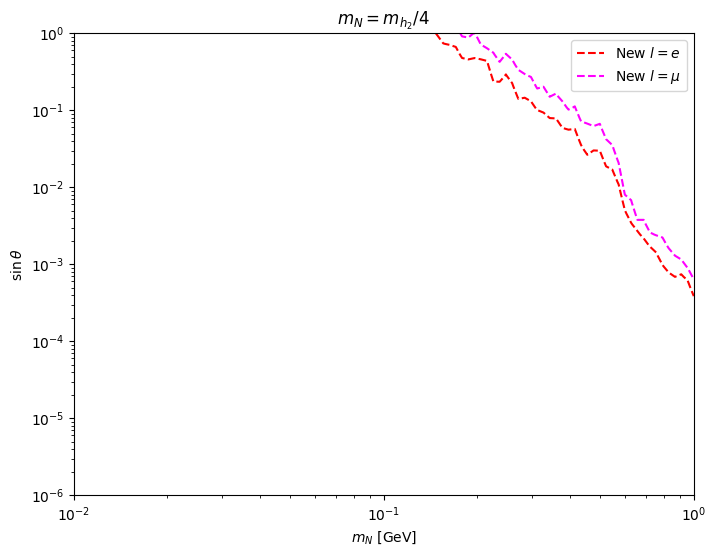

In [5]:
setups = [ 
    ["e_coupling_front_ship_3", r"$l=e$", "red"     ,  "solid"  , 0., 3],
    ["mu_coupling_front_ship_3", r"$l=\mu$"    , "magenta" ,  "solid"  , 0., 3],
]

lines = {"no_star": "solid", "star": "dashed", "no3b": "dotted"}

for setup in setups:
    filename, label, color, ls, alpha, level = setup
    folder = "/home/souvik/codes/FORESEE_fig/dark_scalar/"#"/home/souvik/codes/FORESEE_fig/dark_scalar/"
    
    masses, couplings = [], []
    with open(folder+"400GeV_"+filename+".npy.txt", "r") as f:
        for line in f:
            data = line.strip()
            m, c = data.split(" ")[0], data.split(" ")[-1]
            masses.append(eval(m))
            couplings.append(eval(c))
    plt.plot(masses,couplings, color=color, linestyle="dashed", label="New "+label)

    # masses, couplings = [], []
    # with open(folder+"old/400GeV_"+filename+".npy.txt", "r") as f:
    #     for line in f:
    #         data = line.strip()
    #         m, c = data.split(" ")[0], data.split(" ")[-1]
    #         masses.append(eval(m))
    #         couplings.append(eval(c))
    # plt.plot(masses,couplings, color=color, linestyle="solid", label="Old "+label)
        
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel(r"$m_N$ [GeV]") 
    plt.ylabel(r"$\sin\theta$")
    plt.rcParams["figure.figsize"]=(8,6)
    plt.title(r"$m_N = m_{h_2}/4$")
#     plt.plot([0],[0],label=label, color=color)
# plt.plot([0],[0],linestyle=lines["no_star"], color="black", label="without K*")  
# plt.plot([0],[0],linestyle=lines["no3b"], color="black", label="no 3b decay without K*")  
# plt.plot([0],[0],linestyle=lines["star"], color="black", label="with K*")
plt.xlim(1e-2, 1)
plt.ylim(1e-6, 1)
plt.legend()
plt.savefig("./coupling")

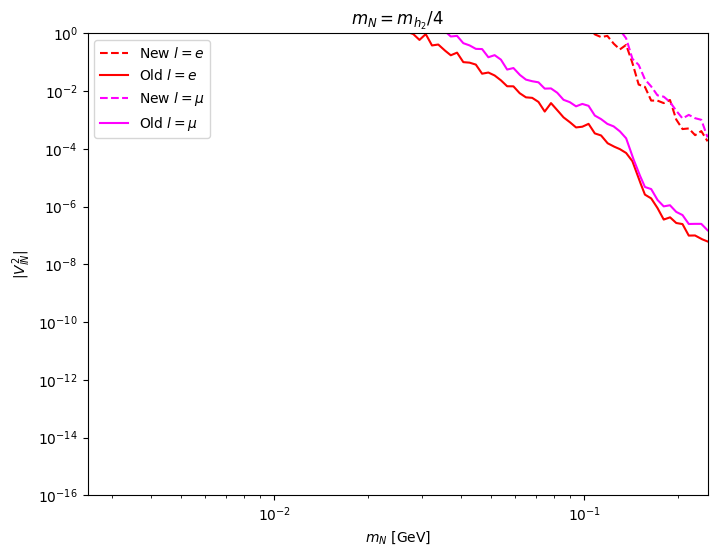

In [4]:
setups = [ 
    ["e_mixing_front_ship_4", r"$l=e$", "red"     ,  "solid"  , 0., 3],
    ["mu_mixing_front_ship_4", r"$l=\mu$"    , "magenta" ,  "solid"  , 0., 3],
]

for setup in setups:
    filename, label, color, ls, alpha, level = setup
    folder = "/home/souvik/codes/FORESEE_fig/dark_scalar/"
    
    masses, couplings = [], []
    with open(folder+"400GeV_"+filename+".npy.txt", "r") as f:
        for line in f:
            data = line.strip()
            m, c = data.split(" ")[0], data.split(" ")[-1]
            masses.append(eval(m)/4)
            couplings.append(eval(c)**2)
    plt.plot(masses,couplings, color=color, linestyle="dashed", label="New "+label)

    masses, couplings = [], []
    with open(folder+"old/400GeV_"+filename+".npy.txt", "r") as f:
        for line in f:
            data = line.strip()
            m, c = data.split(" ")[0], data.split(" ")[-1]
            masses.append(eval(m)/4)
            couplings.append(eval(c)**2)
    plt.plot(masses,couplings, color=color, linestyle="solid", label="Old "+label)
        
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel(r"$m_N$ [GeV]") 
    plt.ylabel(r"$|V_{lN}^2|$")
    plt.rcParams["figure.figsize"]=(8,6)
    plt.title(r"$m_N = m_{h_2}/4$")
#     plt.plot([0],[0],label=label, color=color)
# plt.plot([0],[0],linestyle=lines["no_star"], color="black", label="without K*")  
# plt.plot([0],[0],linestyle=lines["no3b"], color="black", label="no 3b decay without K*")  
# plt.plot([0],[0],linestyle=lines["star"], color="black", label="with K*")
plt.xlim(0.25e-2, 0.25)
plt.ylim(1e-16, 1)
plt.legend()
plt.savefig("./mixing")

/tmp/ipykernel_2597/452031345.py:16: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="solid", clabel=label)
/tmp/ipykernel_2597/452031345.py:21: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dashed", clabel=label)
/tmp/ipykernel_2597/452031345.py:26: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dotted", clabel=label)


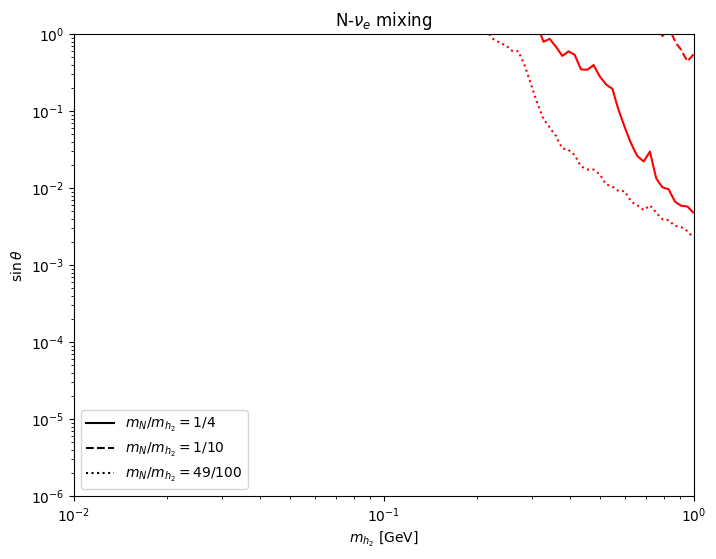

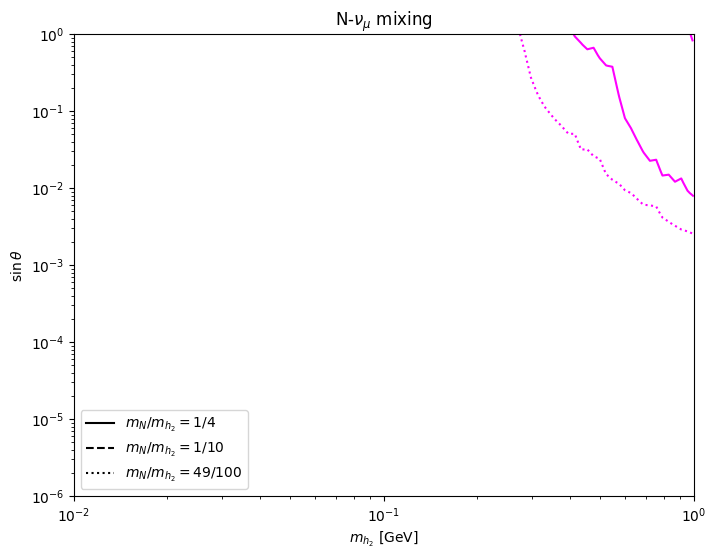

In [9]:
setups = [ 
    ["e_coupling_front_ship_4", r"N-$\nu_e$ mixing", "red"     ,  "solid"  , 0., 3],
    ["mu_coupling_front_ship_4", r"N-$\nu_\mu$ mixing"    , "magenta" ,  "solid"  , 0., 3],
]

lines = {"no_star": "solid", "star": "dashed", "no3b": "dotted"}

for setup in setups:
    filename, label, color, ls, alpha, level = setup
    folder = "/home/souvik/codes/foresee-main/Models/DarkHiggs/model/results/"

    
    masses,couplings,nsignals=np.load(folder+"old/400GeV_"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="solid", clabel=label)
    
    masses,couplings,nsignals=np.load(folder+"1by10/400GeV_"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dashed", clabel=label)

    masses,couplings,nsignals=np.load(folder+"49by100/400GeV_"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dotted", clabel=label)
        
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel(r"$m_{h_2}$ [GeV]") 
    plt.ylabel(r"$\sin \theta$")
    plt.rcParams["figure.figsize"]=(8,6)
    plt.title(label)
    # plt.plot([0],[0],label=label, color=color)
    plt.plot([0],[0],linestyle="solid", color="black", label=r"$m_N/m_{h_2} = 1/4$")  
    plt.plot([0],[0],linestyle="dashed", color="black", label=r"$m_N/m_{h_2} = 1/10$")  
    plt.plot([0],[0],linestyle="dotted", color="black", label=r"$m_N/m_{h_2} = 49/100$")
    plt.xlim(1e-2, 1)
    plt.ylim(1e-6, 1)
    plt.legend(loc = "lower left")
    plt.show()

# plt.savefig("./coupling")

/tmp/ipykernel_2597/237602228.py:15: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="solid", clabel=label)
/tmp/ipykernel_2597/237602228.py:20: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dashed", clabel=label)
/tmp/ipykernel_2597/237602228.py:25: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dotted", clabel=label)


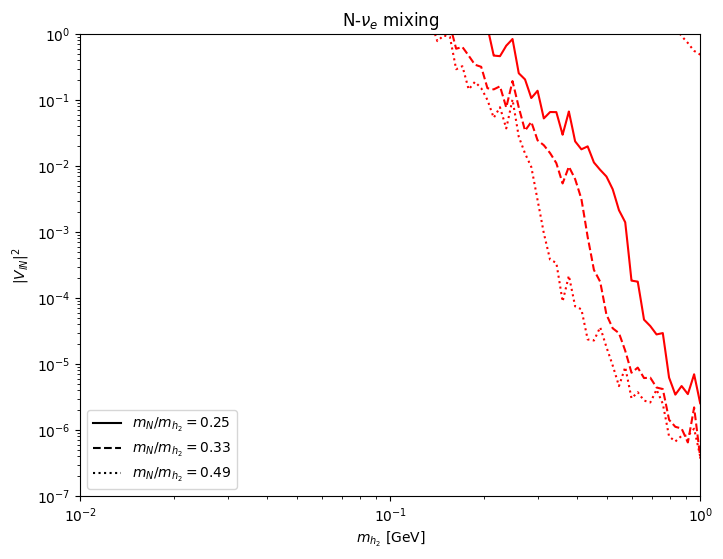

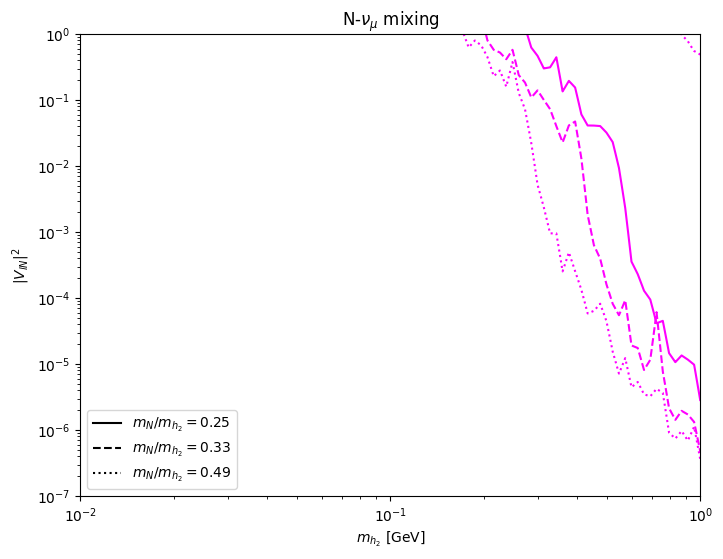

In [31]:
setups = [ 
    ["e_mixing_front_ship_3", r"N-$\nu_e$ mixing", "red"     ,  "solid"  , 0., 3],
    ["mu_mixing_front_ship_3", r"N-$\nu_\mu$ mixing"    , "magenta" ,  "solid"  , 0., 3],
]


for setup in setups:
    filename, label, color, ls, alpha, level = setup
    folder = "/home/souvik/codes/foresee-main/Models/DarkHiggs/model/results/"

    
    masses,couplings,nsignals=np.load(folder+"old/400GeV_"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="solid", clabel=label)
    
    masses,couplings,nsignals=np.load(folder+"1by3/400GeV_"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dashed", clabel=label)

    masses,couplings,nsignals=np.load(folder+"49by100/400GeV_"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dotted", clabel=label)
        
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel(r"$m_{h_2}$ [GeV]") 
    plt.ylabel(r"$|V_{lN}|^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    plt.title(label)
    # plt.plot([0],[0],label=label, color=color)
    plt.plot([0],[0],linestyle="solid", color="black", label=r"$m_N/m_{h_2} = 0.25$")  
    plt.plot([0],[0],linestyle="dashed", color="black", label=r"$m_N/m_{h_2} = 0.33$")  
    plt.plot([0],[0],linestyle="dotted", color="black", label=r"$m_N/m_{h_2} = 0.49$")
    plt.xlim(1e-2, 1)
    plt.ylim(1e-7, 1)
    plt.legend(loc="lower left")
    plt.show()

# plt.savefig("./coupling")

/tmp/ipykernel_33093/683224514.py:21: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="solid", clabel=label)
/tmp/ipykernel_33093/683224514.py:26: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dashed", clabel=label)
/tmp/ipykernel_33093/683224514.py:31: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dotted", clabel=label)


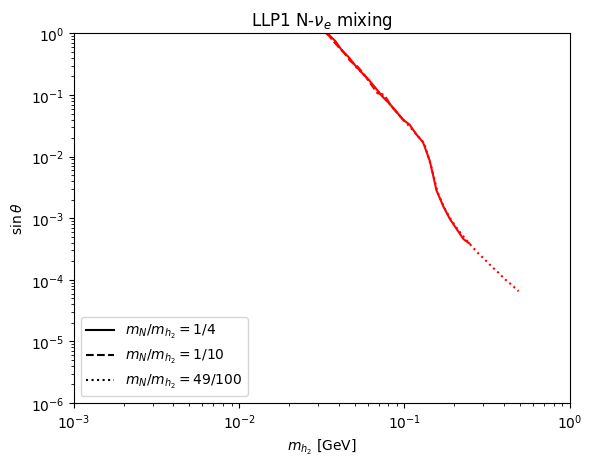

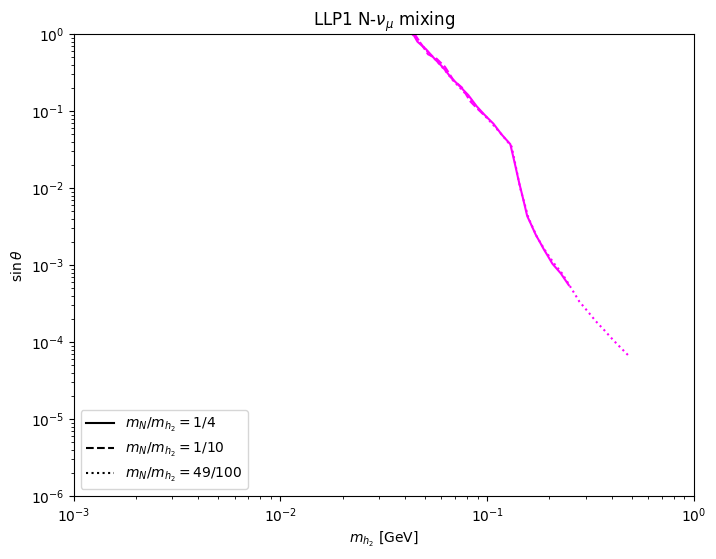

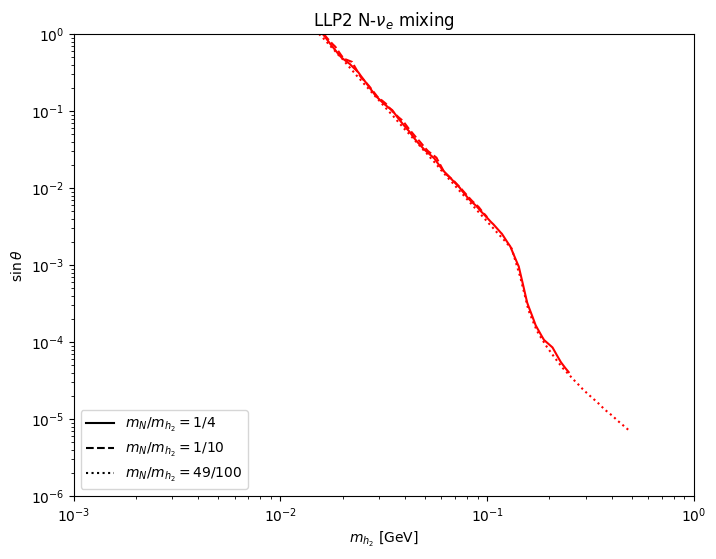

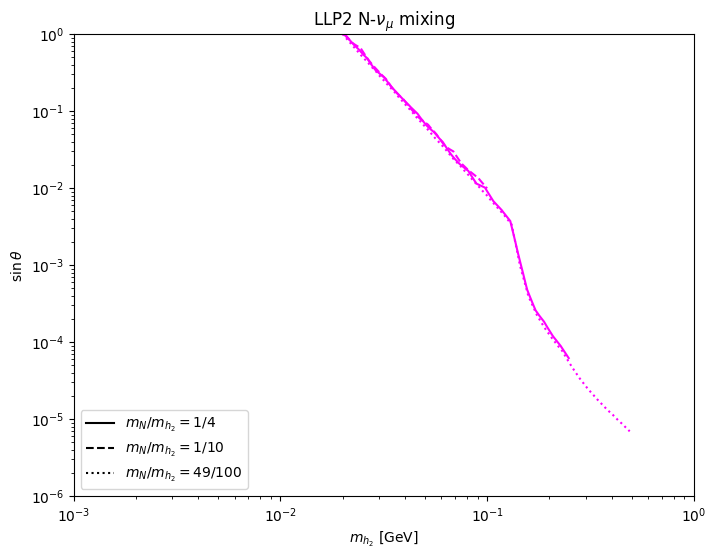

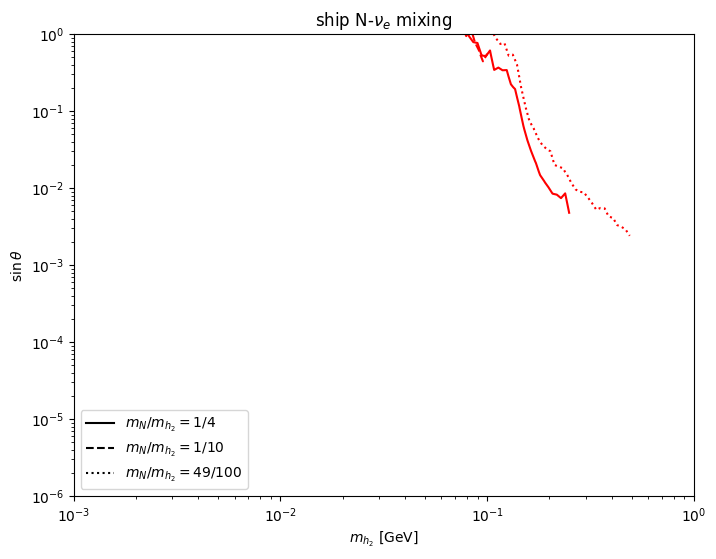

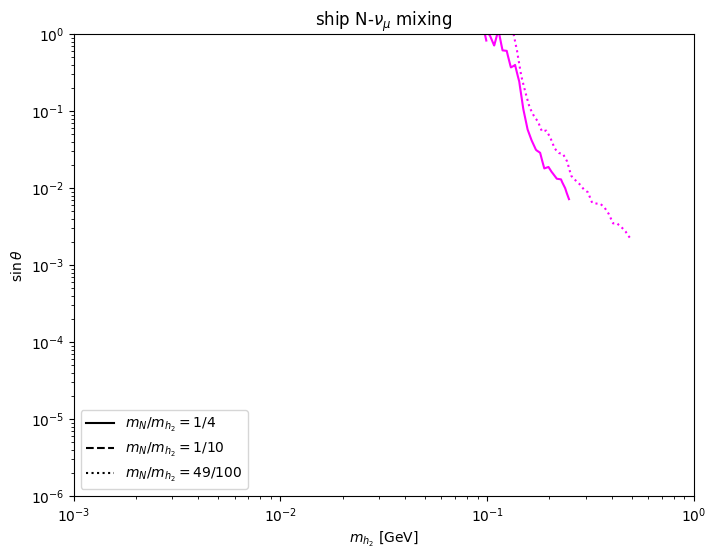

In [3]:
setups = [ 
    ["100TeV_e_coupling_LLP1_4", r"N-$\nu_e$ mixing", "red"     ,  "solid"  , 0., 3],
    ["100TeV_mu_coupling_LLP1_4", r"N-$\nu_\mu$ mixing"    , "magenta" ,  "solid"  , 0., 3],
    ["100TeV_e_coupling_LLP2_4", r"N-$\nu_e$ mixing", "red"     ,  "solid"  , 0., 3],
    ["100TeV_mu_coupling_LLP2_4", r"N-$\nu_\mu$ mixing"    , "magenta" ,  "solid"  , 0., 3],
    ["400GeV_e_coupling_front_ship_4", r"N-$\nu_e$ mixing", "red"     ,  "solid"  , 0., 3],
    ["400GeV_mu_coupling_front_ship_4", r"N-$\nu_\mu$ mixing"    , "magenta" ,  "solid"  , 0., 3],

]

lines = {"no_star": "solid", "star": "dashed", "no3b": "dotted"}

for setup in setups:
    filename, label, color, ls, alpha, level = setup
    folder = "/home/souvik/codes/foresee-main/Models/DarkHiggs/model/results/"
    exp = filename.split("_")[-2]+" "
    
    masses,couplings,nsignals=np.load(folder+"1by4/"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses/4, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="solid", clabel=label)
    
    masses,couplings,nsignals=np.load(folder+"1by10/"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses/10, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dashed", clabel=label)

    masses,couplings,nsignals=np.load(folder+"49by100/"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses*0.49, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dotted", clabel=label)
        
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel(r"$m_{h_2}$ [GeV]") 
    plt.ylabel(r"$\sin \theta$")
    plt.rcParams["figure.figsize"]=(8,6)
    plt.title(exp+label)
    # plt.plot([0],[0],label=label, color=color)
    plt.plot([0],[0],linestyle="solid", color="black", label=r"$m_N/m_{h_2} = 1/4$")  
    plt.plot([0],[0],linestyle="dashed", color="black", label=r"$m_N/m_{h_2} = 1/10$")  
    plt.plot([0],[0],linestyle="dotted", color="black", label=r"$m_N/m_{h_2} = 49/100$")
    plt.xlim(1e-3, 1)
    plt.ylim(1e-6, 1)
    plt.legend(loc = "lower left")
    plt.savefig(f"./{filename}")
    plt.show()

/tmp/ipykernel_2830/3525456082.py:18: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="solid", clabel=label)
/tmp/ipykernel_2830/3525456082.py:23: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dashed", clabel=label)
/tmp/ipykernel_2830/3525456082.py:28: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dotted", clabel=label)


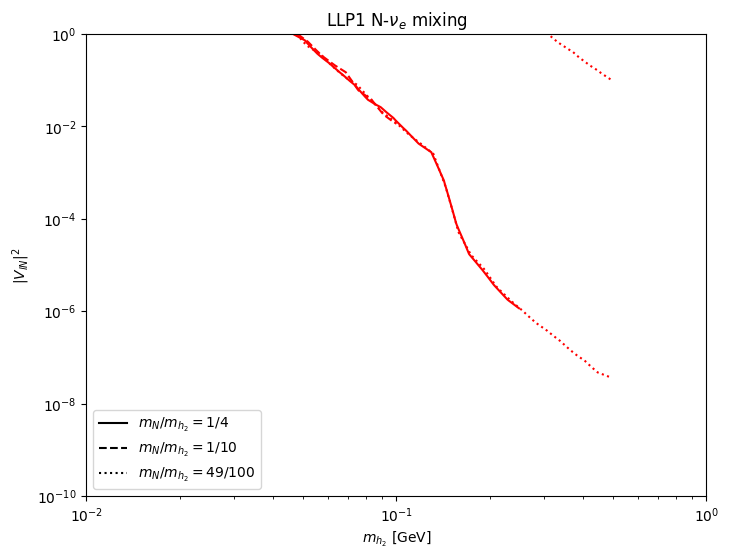

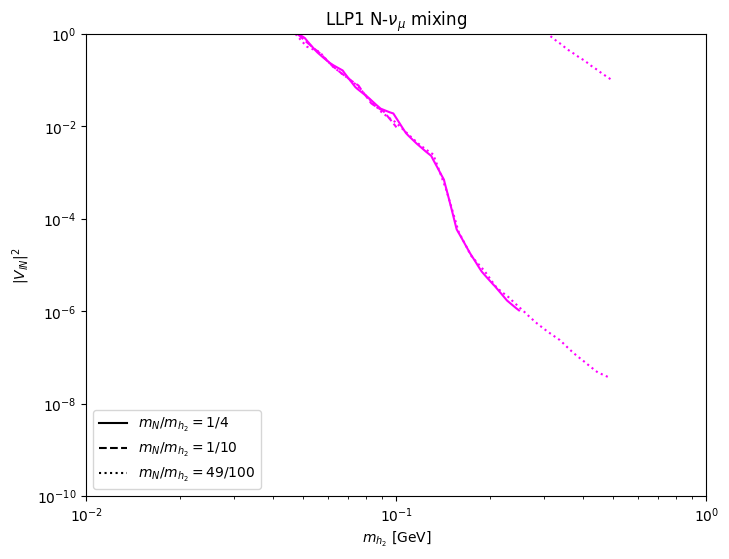

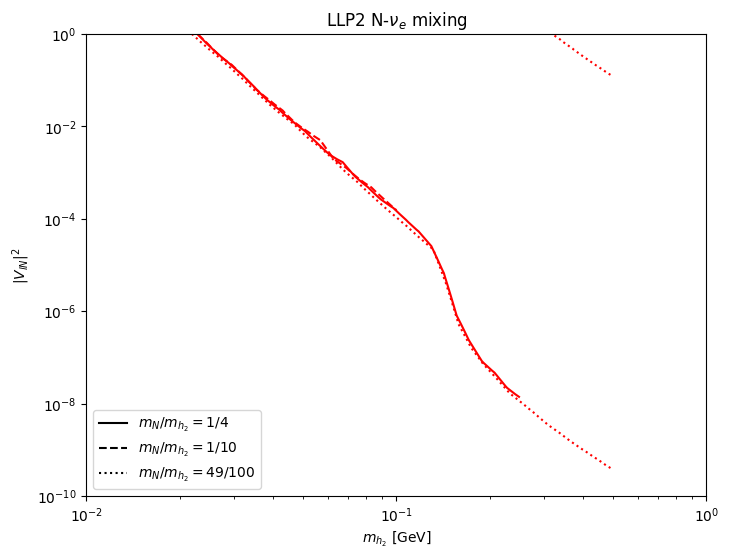

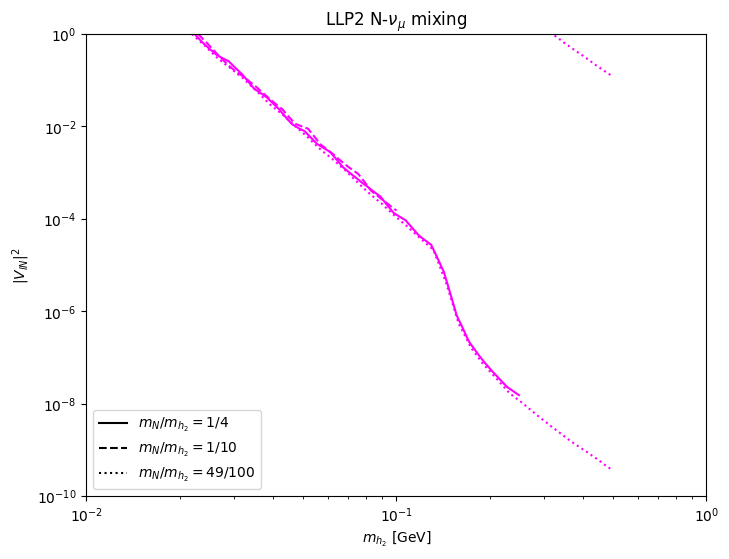

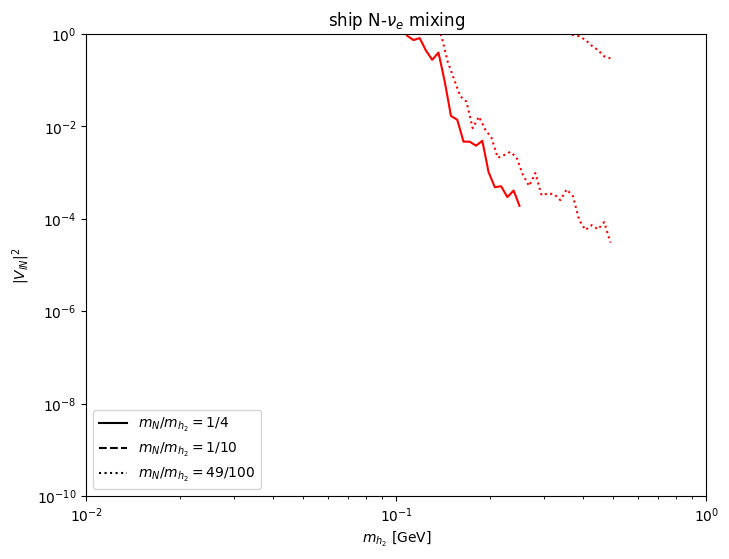

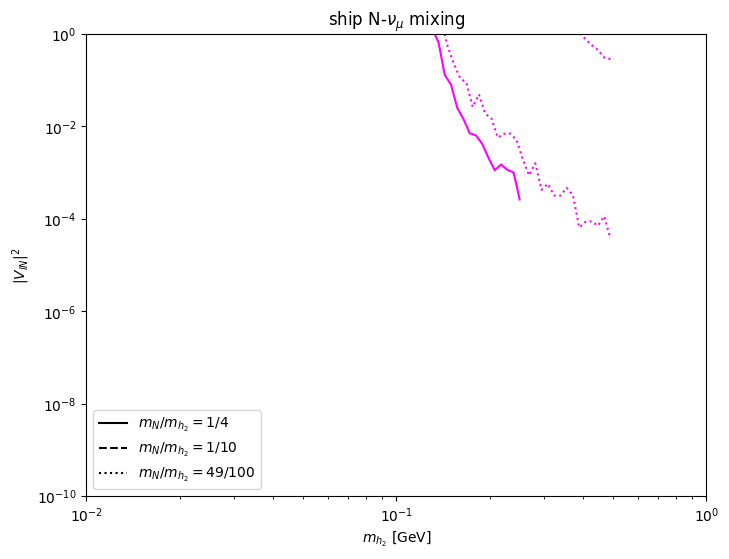

In [3]:
setups = [ 
    ["100TeV_e_mixing_LLP1_4", r"N-$\nu_e$ mixing", "red"     ,  "solid"  , 0., 3],
    ["100TeV_mu_mixing_LLP1_4", r"N-$\nu_\mu$ mixing"    , "magenta" ,  "solid"  , 0., 3],
    ["100TeV_e_mixing_LLP2_4", r"N-$\nu_e$ mixing", "red"     ,  "solid"  , 0., 3],
    ["100TeV_mu_mixing_LLP2_4", r"N-$\nu_\mu$ mixing"    , "magenta" ,  "solid"  , 0., 3],
    ["400GeV_e_mixing_front_ship_4", r"N-$\nu_e$ mixing", "red"     ,  "solid"  , 0., 3],
    ["400GeV_mu_mixing_front_ship_4", r"N-$\nu_\mu$ mixing"    , "magenta" ,  "solid"  , 0., 3],

]

for setup in setups:
    filename, label, color, ls, alpha, level = setup
    folder = "/home/souvik/codes/foresee-main/Models/DarkHiggs/model/results/"
    exp = filename.split("_")[-2]+" "
    masses,couplings,nsignals=np.load(folder+"old/"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(0.25*masses, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="solid", clabel=label)
    
    masses,couplings,nsignals=np.load(folder+"1by10/"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses/10, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dashed", clabel=label)

    masses,couplings,nsignals=np.load(folder+"49by100/"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses*0.49, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles="dotted", clabel=label)
        
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel(r"$m_{h_2}$ [GeV]") 
    plt.ylabel(r"$|V_{lN}|^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    plt.title(exp + label)
    # plt.plot([0],[0],label=label, color=color)
    plt.plot([0],[0],linestyle="solid", color="black", label=r"$m_N/m_{h_2} = 1/4$")  
    plt.plot([0],[0],linestyle="dashed", color="black", label=r"$m_N/m_{h_2} = 1/10$")  
    plt.plot([0],[0],linestyle="dotted", color="black", label=r"$m_N/m_{h_2} = 49/100$")
    plt.xlim(1e-2, 1)
    plt.ylim(1e-10, 1)
    plt.legend(loc = "lower left")
    plt.savefig(f"./{filename}")
    plt.show()